# Paper figures

Image grids have no titles and no labels. A wider white gap is the only mark between groups. PNG and PDF files are written to `results/artifacts/figures_paper/`.

The class row is not class-conditional generation. The autoencoders reconstruct the first test image of class 0. Vanilla GAN, DCGAN, and DDPM contribute the saved sample that the trained MLP assigns to class 0 with the highest confidence.


In [1]:
%matplotlib inline

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib import font_manager

def find_artifacts():
    here = Path.cwd().resolve()
    for root in [here, *here.parents]:
        for path in (root / "results" / "artifacts", root / "artifacts"):
            if (path / "test8.pt").exists():
                return path
    raise FileNotFoundError("Could not find results/artifacts.")

ART = find_artifacts()
OUT = ART / "figures_paper"
OUT.mkdir(parents=True, exist_ok=True)
ROOT = ART.parent.parent if ART.parent.name == "results" else ART.parent
import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

available = {font.name for font in font_manager.fontManager.ttflist}
for family in ("Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"):
    if family in available:
        plt.rcParams["font.family"] = family
        break
plt.rcParams.update({
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 7.5,
    "legend.frameon": False,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

INK = "#1c1c1c"
COLORS = {
    "Vanilla AE": "#0072B2",
    "Sparse AE": "#E69F00",
    "VAE": "#009E73",
    "Generator": "#D55E00",
    "Discriminator": "#0072B2",
    "DDPM": "#CC79A7",
}

def load(name, filename):
    return torch.load(ART / name / filename, map_location="cpu", weights_only=False)

def images_of(payload):
    if isinstance(payload, dict):
        return payload["images"].detach().float().clamp(0, 1).cpu()
    return payload.detach().float().clamp(0, 1).cpu()

def plane(image):
    image = image.detach().float().clamp(0, 1).cpu()
    if image.ndim == 3:
        image = image[0]
    return image.numpy()

def tile(images, ncol, gap):
    frames = [plane(image) for image in images]
    height, width = frames[0].shape
    nrow = int(np.ceil(len(frames) / ncol))
    canvas = np.ones((nrow * height + (nrow - 1) * gap, ncol * width + (ncol - 1) * gap), dtype=np.float32)
    for index, frame in enumerate(frames):
        row, col = divmod(index, ncol)
        top = row * (height + gap)
        left = col * (width + gap)
        canvas[top:top + height, left:left + width] = frame
    return canvas

def stack(blocks, gap, axis):
    if axis == 0:
        width = max(block.shape[1] for block in blocks)
        height = sum(block.shape[0] for block in blocks) + gap * (len(blocks) - 1)
        canvas = np.ones((height, width), dtype=np.float32)
        top = 0
        for block in blocks:
            left = (width - block.shape[1]) // 2
            canvas[top:top + block.shape[0], left:left + block.shape[1]] = block
            top += block.shape[0] + gap
        return canvas
    height = max(block.shape[0] for block in blocks)
    width = sum(block.shape[1] for block in blocks) + gap * (len(blocks) - 1)
    canvas = np.ones((height, width), dtype=np.float32)
    left = 0
    for block in blocks:
        top = (height - block.shape[0]) // 2
        canvas[top:top + block.shape[0], left:left + block.shape[1]] = block
        left += block.shape[1] + gap
    return canvas

def save_grid(canvas, stem):
    height, width = canvas.shape
    figure = plt.figure(figsize=(width / 300, height / 300), dpi=300)
    axis = figure.add_axes([0, 0, 1, 1])
    axis.imshow(canvas, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axis.set_axis_off()
    figure.savefig(OUT / f"{stem}.png", dpi=300)
    figure.savefig(OUT / f"{stem}.pdf")
    plt.show()

def read_json(name):
    return json.loads((ART / name / "history.json").read_text(encoding="utf-8"))

print("artifacts", ART)


artifacts C:\Users\Alif Akbar Hafiz\Desktop\Perbinusan\5th Semester\1_DeepLearning\2_Assignment\results\artifacts


## Figures 1–4

Rows and blocks are separated only by white space.


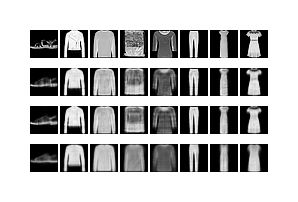

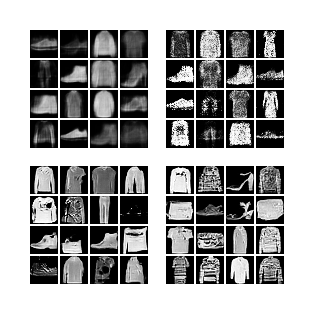

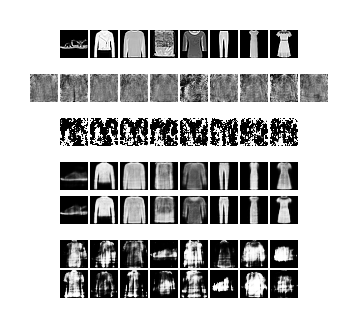

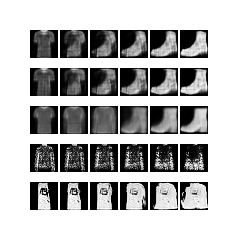

In [2]:
originals = images_of(torch.load(ART / "test8.pt", map_location="cpu", weights_only=False))
figure1 = stack([
    tile(originals, 8, gap=2),
    tile(images_of(load("vanilla_ae", "recon.pt")), 8, gap=2),
    tile(images_of(load("sparse_ae", "recon.pt")), 8, gap=2),
    tile(images_of(load("vae", "recon.pt")), 8, gap=2),
], gap=10, axis=0)
save_grid(figure1, "figure1_reconstruction")

blocks = [
    tile(images_of(load(name, "samples_grid.pt")), 4, gap=2)
    for name in ("vae", "vanilla_gan", "dcgan", "ddpm")
]
top = stack(blocks[:2], gap=18, axis=1)
bottom = stack(blocks[2:], gap=18, axis=1)
save_grid(stack([top, bottom], gap=18, axis=0), "figure2_samples")

frozen = images_of(load("mlp", "frozen_recon.pt"))
vanilla = images_of(load("vanilla_ae", "recon.pt"))
prior = images_of(load("mlp", "prior_samples.pt"))
figure3 = stack([
    tile(originals, 8, gap=2),
    tile(images_of(load("mlp", "class_projections.pt")), 10, gap=2),
    tile(images_of(load("mlp", "latent_projections.pt")), 8, gap=2),
    stack([
        tile(frozen, 8, gap=2),
        tile(vanilla, 8, gap=2),
    ], gap=6, axis=0),
    tile(prior, 8, gap=2),
], gap=16, axis=0)
save_grid(figure3, "figure3_mlp")

strips = [
    tile(images_of(load(name, "interp.pt")), 6, gap=2)
    for name in ("vanilla_ae", "sparse_ae", "vae", "vanilla_gan", "dcgan")
]
save_grid(stack(strips, gap=10, axis=0), "figure4_interpolation")


## Figure 5

The curves keep their axis labels and legend. The reverse chain under them has no step numbers.


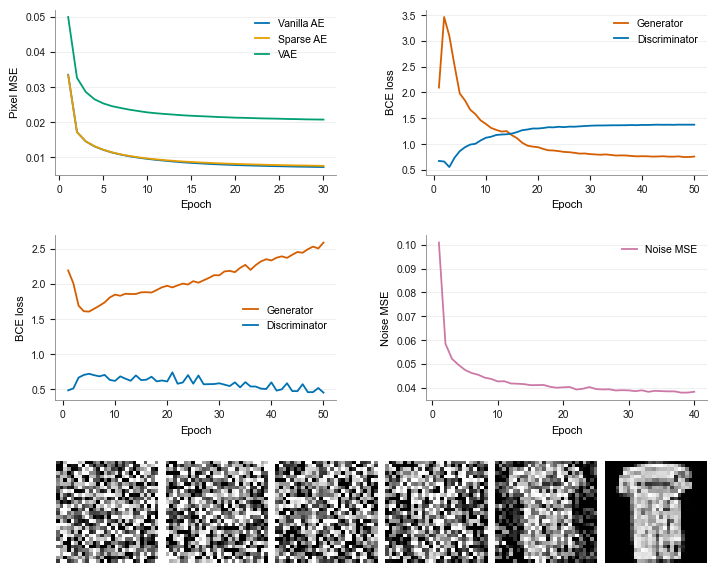

In [3]:
vanilla_hist = read_json("vanilla_ae")
sparse_hist = read_json("sparse_ae")
vae_hist = read_json("vae")
gan_hist = read_json("vanilla_gan")
dcgan_hist = read_json("dcgan")
ddpm_hist = read_json("ddpm")
chain = tile(images_of(load("ddpm", "trajectory.pt")), 6, gap=2)

def epochs(values):
    return range(1, len(values) + 1)

def style_axis(axis, ylabel):
    axis.set_xlabel("Epoch")
    axis.set_ylabel(ylabel)
    axis.tick_params(colors=INK)
    axis.yaxis.grid(True, linewidth=0.4, color="#e4e4e4")
    axis.set_axisbelow(True)
    for spine in ("left", "bottom"):
        axis.spines[spine].set_color("#888888")

figure = plt.figure(figsize=(7.2, 6.15))
grid = figure.add_gridspec(3, 2, height_ratios=[1, 1, 0.62], hspace=0.42, wspace=0.32, left=0.08, right=0.985, top=0.97, bottom=0.07)

axis = figure.add_subplot(grid[0, 0])
axis.plot(epochs(vanilla_hist["recon_loss"]), vanilla_hist["recon_loss"], color=COLORS["Vanilla AE"], lw=1.3, label="Vanilla AE")
axis.plot(epochs(sparse_hist["recon_loss"]), sparse_hist["recon_loss"], color=COLORS["Sparse AE"], lw=1.3, label="Sparse AE")
axis.plot(epochs(vae_hist["recon_loss"]), vae_hist["recon_loss"], color=COLORS["VAE"], lw=1.3, label="VAE")
style_axis(axis, "Pixel MSE")
axis.legend(loc="upper right", handlelength=1.4)

axis = figure.add_subplot(grid[0, 1])
axis.plot(epochs(gan_hist["g_loss"]), gan_hist["g_loss"], color=COLORS["Generator"], lw=1.3, label="Generator")
axis.plot(epochs(gan_hist["d_loss"]), gan_hist["d_loss"], color=COLORS["Discriminator"], lw=1.3, label="Discriminator")
style_axis(axis, "BCE loss")
axis.legend(loc="upper right", handlelength=1.4)

axis = figure.add_subplot(grid[1, 0])
axis.plot(epochs(dcgan_hist["g_loss"]), dcgan_hist["g_loss"], color=COLORS["Generator"], lw=1.3, label="Generator")
axis.plot(epochs(dcgan_hist["d_loss"]), dcgan_hist["d_loss"], color=COLORS["Discriminator"], lw=1.3, label="Discriminator")
style_axis(axis, "BCE loss")
axis.legend(loc="center right", handlelength=1.4)

axis = figure.add_subplot(grid[1, 1])
axis.plot(epochs(ddpm_hist["train_loss"]), ddpm_hist["train_loss"], color=COLORS["DDPM"], lw=1.3, label="Noise MSE")
style_axis(axis, "Noise MSE")
axis.legend(loc="upper right", handlelength=1.4)

strip = grid[2, :].subgridspec(1, 1)
axis = figure.add_subplot(strip[0, 0])
axis.imshow(chain, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
axis.set_axis_off()
figure.savefig(OUT / "figure5_curves.png", dpi=300, bbox_inches="tight", pad_inches=0.03)
figure.savefig(OUT / "figure5_curves.pdf", bbox_inches="tight", pad_inches=0.03)
plt.show()


## One class across the generators

One row, class 0. The three autoencoders reconstruct the first test image of that class. Vanilla GAN, DCGAN, and DDPM show the saved sample that the trained MLP assigns to that class with the highest confidence.


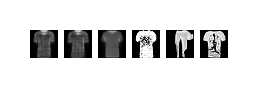

In [4]:
from src.data import get_splits
from src.models import MLPClassifier, VanillaAE, VAE

CLASS = 0
_, _, test_set = get_splits()
exemplar = None
for index in range(len(test_set)):
    image, label = test_set[index]
    if int(label) == CLASS:
        exemplar = image.unsqueeze(0)
        break

def load_module(module, name, key):
    checkpoint = load(name, "checkpoint.pt")
    module.load_state_dict(checkpoint[key])
    module.eval()
    return module

vanilla_ae = load_module(VanillaAE(), "vanilla_ae", "model")
sparse_ae = load_module(VanillaAE(), "sparse_ae", "model")
vae = load_module(VAE(), "vae", "model")
classifier = load_module(MLPClassifier(), "mlp", "classifier")

with torch.no_grad():
    vanilla_class, _ = vanilla_ae(exemplar)
    sparse_class, _ = sparse_ae(exemplar)
    mu, _ = vae.encode(exemplar)
    vae_class = vae.decode(mu)

def best_of_class(samples, label):
    with torch.no_grad():
        logits = []
        for start in range(0, samples.size(0), 256):
            logits.append(classifier(samples[start:start + 256]))
        probability = torch.softmax(torch.cat(logits), dim=1)
        assigned = probability.argmax(dim=1)
        scores = probability[:, label].clone()
        scores[assigned != label] = -1
        if scores.max() < 0:
            scores = probability[:, label]
        return samples[int(scores.argmax())]

gan_class = best_of_class(images_of(load("vanilla_gan", "samples_fid.pt")), CLASS)
dcgan_class = best_of_class(images_of(load("dcgan", "samples_fid.pt")), CLASS)
ddpm_class = best_of_class(images_of(load("ddpm", "samples_fid.pt")), CLASS)
row = tile([
    vanilla_class[0],
    sparse_class[0],
    vae_class[0],
    gan_class,
    dcgan_class,
    ddpm_class,
], ncol=6, gap=6)
save_grid(row, "figure_by_class")


## Uncurated sample pages

One page per model, in saved or test-set order. Large frames run down the left, then medium frames, then two columns of small frames. A thin white gap is the only separator.

Vanilla AE and sparse AE have no prior samples, so those pages reconstruct the first test images. VAE, both GANs, and DDPM use `samples_fid.pt`. The MLP page draws from the test-set latent prior saved with that checkpoint.


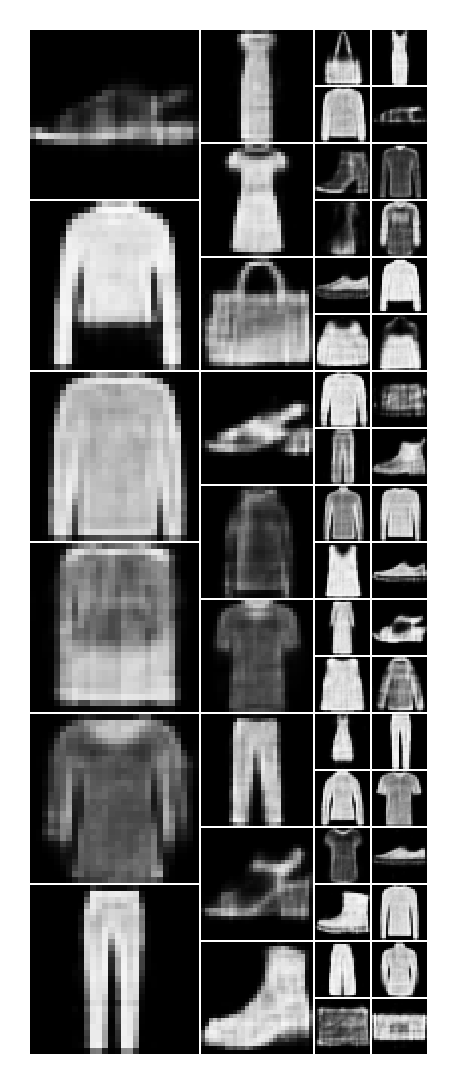

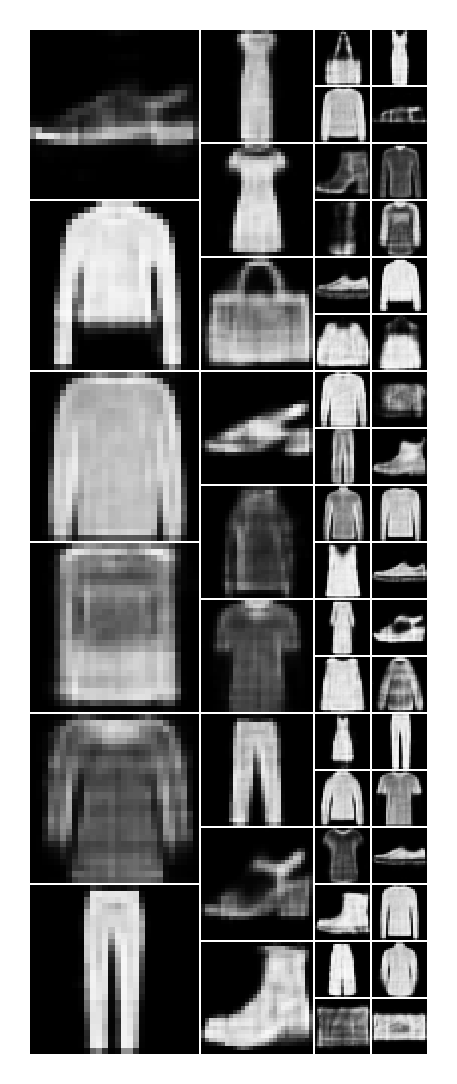

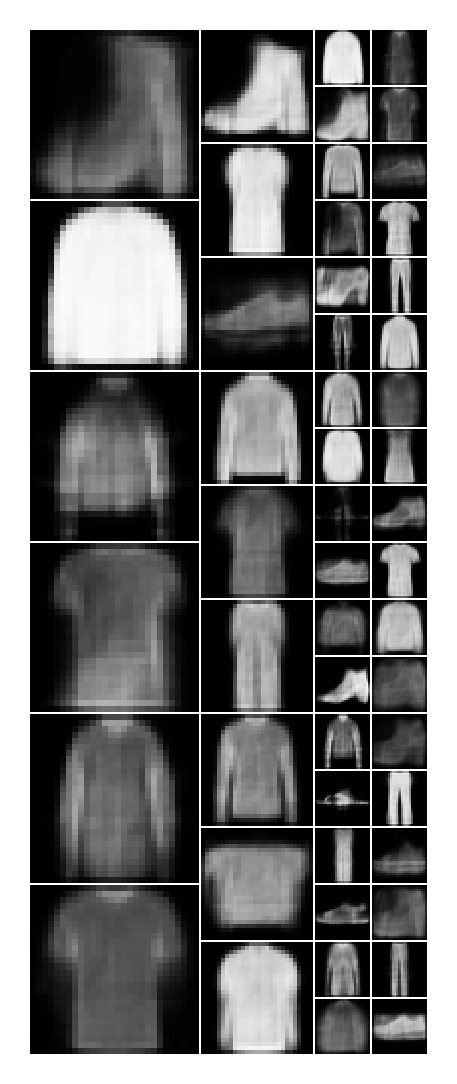

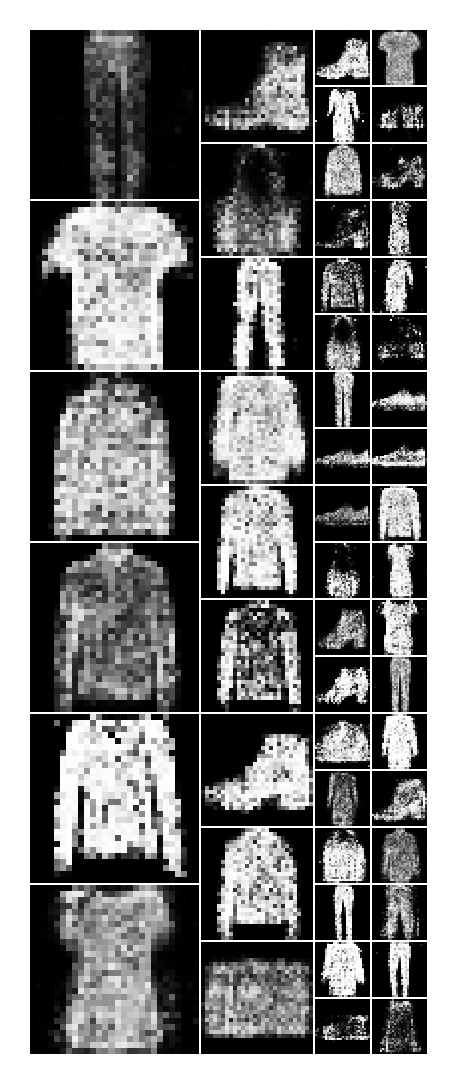

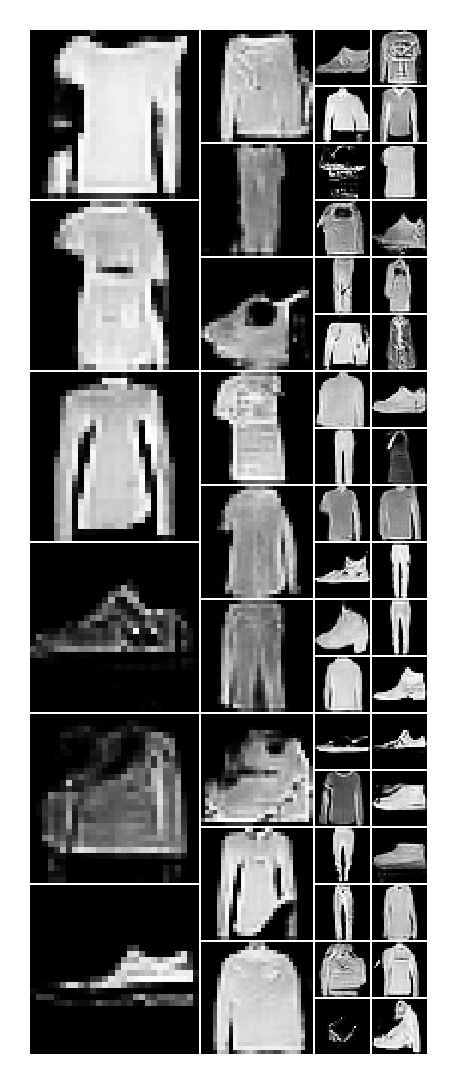

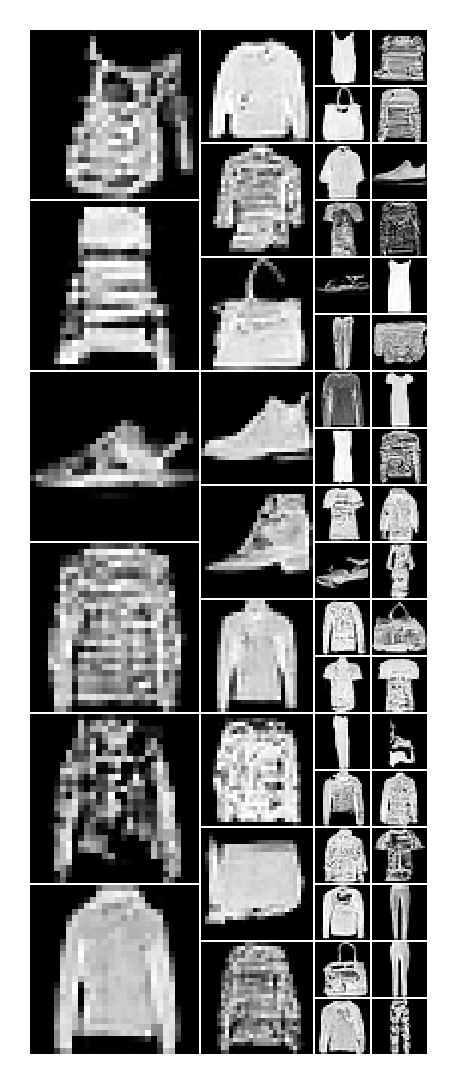

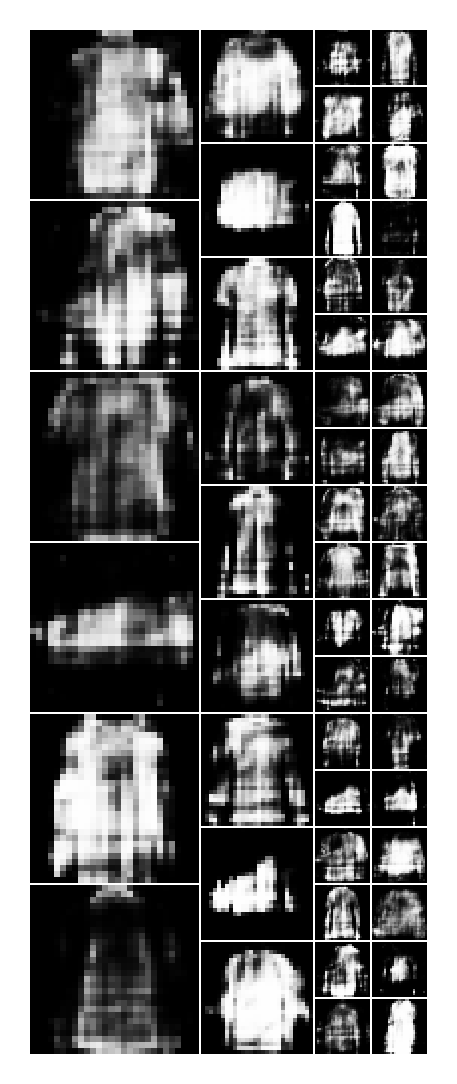

wrote C:\Users\Alif Akbar Hafiz\Desktop\Perbinusan\5th Semester\1_DeepLearning\2_Assignment\results\artifacts\figures_paper


In [5]:
from PIL import Image

from src.config import SEED
from src.data import get_splits
from src.models import MLPDecoder, VanillaAE

def collage(images):
    gap = 2
    columns = (169, 112, 55, 55)
    height = 1024
    width = sum(columns) + gap * (len(columns) - 1)
    canvas = np.ones((height, width), dtype=np.float32)
    cursor = 0
    left = 0
    for size in columns:
        top = 0
        while top + size <= height:
            frame = plane(images[cursor])
            picture = Image.fromarray((frame * 255).astype(np.uint8), mode="L")
            picture = picture.resize((size, size), Image.Resampling.NEAREST)
            canvas[top:top + size, left:left + size] = np.asarray(picture, dtype=np.float32) / 255
            cursor += 1
            top += size + gap
        left += size + gap
    return canvas

def page_length():
    gap = 2
    height = 1024
    total = 0
    for size in (169, 112, 55, 55):
        total += (height + gap) // (size + gap)
    return total

def reconstruct_test(name, count):
    module = VanillaAE()
    module.load_state_dict(load(name, "checkpoint.pt")["model"])
    module.eval()
    _, _, test_set = get_splits()
    batch = torch.stack([test_set[index][0] for index in range(count)])
    with torch.no_grad():
        recon, _ = module(batch)
    return recon

def mlp_prior(count):
    stats = load("mlp", "z_test.pt")
    decoder = MLPDecoder()
    decoder.load_state_dict(load("mlp", "checkpoint.pt")["decoder"])
    decoder.eval()
    torch.manual_seed(SEED)
    epsilon = torch.randn(count, stats["mu"].numel())
    with torch.no_grad():
        return decoder(stats["mu"] + stats["sigma"] * epsilon)

count = page_length()
pages = {
    "uncurated_vanilla_ae": reconstruct_test("vanilla_ae", count),
    "uncurated_sparse_ae": reconstruct_test("sparse_ae", count),
    "uncurated_vae": images_of(load("vae", "samples_fid.pt")),
    "uncurated_vanilla_gan": images_of(load("vanilla_gan", "samples_fid.pt")),
    "uncurated_dcgan": images_of(load("dcgan", "samples_fid.pt")),
    "uncurated_ddpm": images_of(load("ddpm", "samples_fid.pt")),
    "uncurated_mlp": mlp_prior(count),
}
for stem, images in pages.items():
    save_grid(collage(images), stem)
print("wrote", OUT)


## Best generator

DCGAN has the lowest FID of the models that sample a prior. Fifteen of its saved samples, drawn with the project seed, are packed as three large frames over two rows of six. The gap is the only separator.


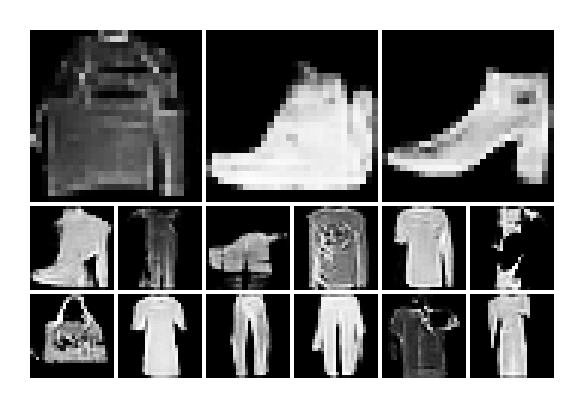

wrote C:\Users\Alif Akbar Hafiz\Desktop\Perbinusan\5th Semester\1_DeepLearning\2_Assignment\results\artifacts\figures_paper\best_dcgan.png


In [6]:
from PIL import Image

from src.config import SEED

def showcase(images):
    gap = 4
    small = 84
    large = 2 * small + gap
    width = 6 * small + 5 * gap
    height = large + 2 * small + 2 * gap
    canvas = np.ones((height, width), dtype=np.float32)
    slots = []
    for index in range(3):
        slots.append((index * (large + gap), 0, large))
    for row in range(2):
        top = large + gap + row * (small + gap)
        for index in range(6):
            slots.append((index * (small + gap), top, small))
    generator = torch.Generator().manual_seed(SEED)
    order = torch.randperm(images.size(0), generator=generator)[:len(slots)]
    for chosen, (left, top, size) in zip(order.tolist(), slots):
        frame = plane(images[chosen])
        picture = Image.fromarray((frame * 255).astype(np.uint8), mode="L")
        picture = picture.resize((size, size), Image.Resampling.NEAREST)
        canvas[top:top + size, left:left + size] = np.asarray(picture, dtype=np.float32) / 255
    return canvas

page = showcase(images_of(load("dcgan", "samples_fid.pt")))
save_grid(page, "best_dcgan")
print("wrote", OUT / "best_dcgan.png")
